In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LinearSegmentedColormap

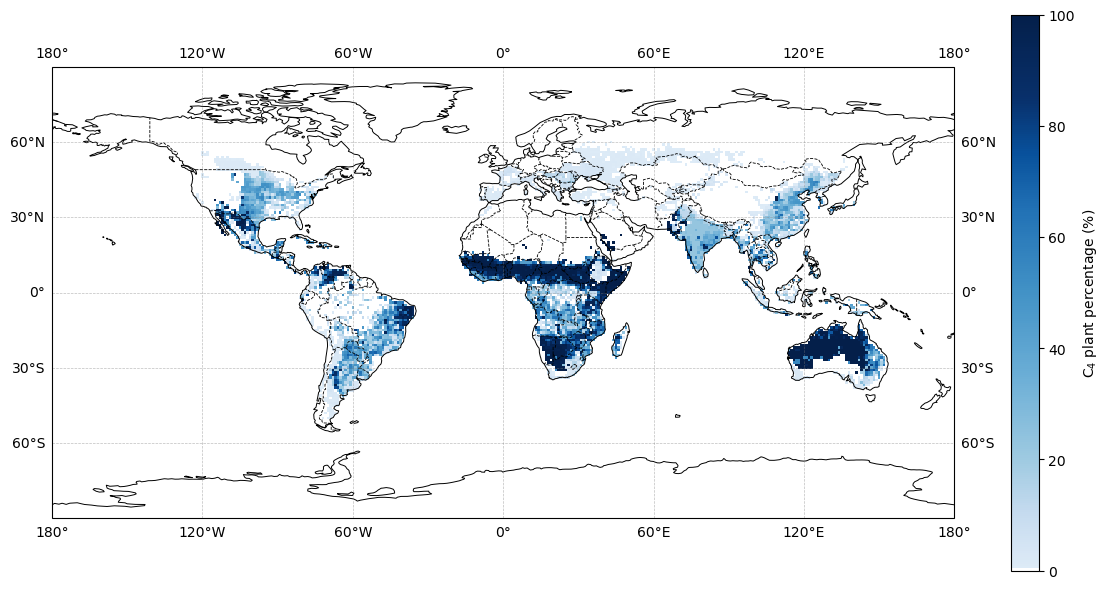

In [ ]:

# Load the ASCII grid manually
data = np.loadtxt('resources/c4_percent_1d.asc', skiprows=6)  # Skip the header

# Replace NODATA values with NaN
data[data == -99] = np.nan

# Coordinate arrays (1° resolution)
lon = np.linspace(-180, 179, 360)  # 360 columns
lat = np.linspace(89, -90, 180)    # 180 rows (top to bottom)

white_to_green = LinearSegmentedColormap.from_list(
    'white_to_green', [
        (0.0,   '#ffffff'),   # 0% – white
        (0.001, '#def2c3'),   # very pale green
        (0.1,   '#ccebb0'),   # pale lime
        (0.2,   '#bae29d'),   # soft light green
        (0.35,  '#97d487'),   # moderate light green
        (0.5,   '#78c679'),   # medium green
        (0.65,  '#55ae63'),   # deeper green
        (0.75,  '#3a994f'),   # even deeper
        (0.85,  '#238443'),   # dark green
        (1.0,   '#006837')    # very dark green
    ],
    N=256
)

white_to_red = LinearSegmentedColormap.from_list(
    'white_to_red', [
        (0.0,   '#ffffff'),   # 0% – white
        (0.001, '#fddbc7'),   # very pale red
        (0.1,   '#fcbba1'),   # pale salmon
        (0.2,   '#fc9272'),   # light red-orange
        (0.35,  '#fb6a4a'),   # moderate light red
        (0.5,   '#ef3b2c'),   # medium red
        (0.65,  '#cb181d'),   # deeper red
        (0.75,  '#a50f15'),   # dark red
        (0.85,  '#67000d'),   # very dark red
        (1.0,   '#49000a')    # almost black-red
    ],
    N=256
)

white_to_blue = LinearSegmentedColormap.from_list(
    'white_to_blue', [
        (0.0,   '#ffffff'),   # 0% – white
        (0.001, '#deebf7'),   # very pale blue
        (0.1,   '#c6dbef'),   # pale sky blue
        (0.2,   '#9ecae1'),   # light blue
        (0.35,  '#6baed6'),   # moderate light blue
        (0.5,   '#4292c6'),   # medium blue
        (0.65,  '#2171b5'),   # deeper blue
        (0.75,  '#08519c'),   # dark blue
        (0.85,  '#08306b'),   # very dark blue
        (1.0,   '#041f4a')    # almost black-blue
    ],
    N=256
)

# Plot
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_global()
ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.6, linestyle='--')
ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# Show raster with custom colormap
img = ax.pcolormesh(lon, lat, data, cmap=white_to_blue, shading='auto',
                    transform=ccrs.PlateCarree(), vmin=0, vmax=100)

# Add colorbar
cbar = plt.colorbar(img, ax=ax, orientation='vertical')
cbar.set_label('C$_4$ plant percentage (%)')

plt.tight_layout()

plt.savefig('plots/evolution/c4_plant_distribution.png', dpi=300, bbox_inches='tight')